# Phase 1 · 02 · Balanced subset

**Goal:** select exactly the samples the paper's classifier used: CRC and control samples, with equal numbers of each.

1. Why the classes are balanced, and why inside each study.
2. Read the paper's balanced set from the published metadata and confirm it is balanced inside every study.
3. Save the sample list for notebook 03.

## Setup

This notebook only needs the metadata. Outputs go to `data/processed/phase_1/02_balanced_subset/` and `results/figures/phase_1/02_balanced_subset/`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display


def find_project_root() -> Path:
    """Walk up from the current folder to the one that holds requirements.txt."""
    folder = Path.cwd()
    while not (folder / "requirements.txt").exists():
        if folder.parent == folder:
            raise FileNotFoundError("No requirements.txt above this folder.")
        folder = folder.parent
    return folder


PROJECT_ROOT = find_project_root()
RAW = PROJECT_ROOT / "data" / "raw" / "zenodo"
PROCESSED = PROJECT_ROOT / "data" / "processed" / "phase_1" / "02_balanced_subset"
FIGURES = PROJECT_ROOT / "results" / "figures" / "phase_1" / "02_balanced_subset"
PROCESSED.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

figure_number = 0


def show_figure(fig: plt.Figure, name: str, caption: str) -> None:
    global figure_number
    figure_number += 1
    fig.savefig(FIGURES / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
    display(Markdown(f"**Figure {figure_number}.** {caption}"))


metadata = pd.read_csv(RAW / "Metadata.all.samples.tsv", sep="\t", index_col="Sample_ID", dtype={"Sample_ID": str})
crc_ctr = metadata[metadata["Condition"].isin(["CRC", "CTR"])]
print(f"{len(crc_ctr):,} CRC and control samples out of {len(metadata):,}")

6,779 CRC and control samples out of 8,330


## 1. Why balance, and why inside each study?

The paper's Methods: *"We applied random subsampling to both training and testing sets, such that the proportion of cases and controls are equal in both sets."*

**Balance.** If 80% of the samples were cancer, a model could score 80% accuracy by always answering "cancer". With equal numbers, the only way to do well is to find the real signal.

**Inside each study.** Suppose study A is 90% cancer and study B is 90% controls. Each study has its own measurement quirks, so a model could learn "looks like study A, so cancer" without learning anything about cancer. If every study is 50/50, knowing the study tells the model nothing about the label.

Random subsampling can't be redone exactly in another language, because R and Python draw different random numbers. So we don't redraw. The paper published its chosen samples in the metadata column `Used_in_balanced_model`, and we use that column.

## 2. Is the published set balanced inside every study?

If every study was balanced, each one keeps as many CRC as controls, and that number is the size of its smaller class. The table compares what the flag keeps with that expectation.

In [2]:
flagged = crc_ctr[crc_ctr["Used_in_balanced_model"] == "Yes"]

before = crc_ctr.groupby(["Cohort", "Condition"]).size().unstack("Condition", fill_value=0)
kept = flagged.groupby(["Cohort", "Condition"]).size().unstack("Condition", fill_value=0)
per_study = pd.DataFrame({
    "CRC before": before["CRC"],
    "CTR before": before["CTR"],
    "smaller class": before.min(axis=1),
    "CRC kept": kept["CRC"],
    "CTR kept": kept["CTR"],
}).sort_values("smaller class")

assert (per_study["CRC kept"] == per_study["smaller class"]).all()
assert (per_study["CTR kept"] == per_study["smaller class"]).all()
print("In all", len(per_study), "studies, the flag keeps the smaller class size of both CRC and CTR.")
per_study

In all 27 studies, the flag keeps the smaller class size of both CRC and CTR.


,CRC before,CTR before,smaller class,CRC kept,CTR kept
Cohort,,,,,
HanniganGD_2018,17,16,16,16,16
GaoR_2021,16,21,16,16,16
DengX_2018,17,33,17,17,17
ZhouZ_2022,22,18,18,18,18
ThomasAM_2019_1,29,24,24,24,24
DuX_2022,27,33,27,27,27
ThomasAM_2019_2,32,28,28,28,28
XuJ_2022,30,99,30,30,30
YangTW_2019,37,120,37,37,37


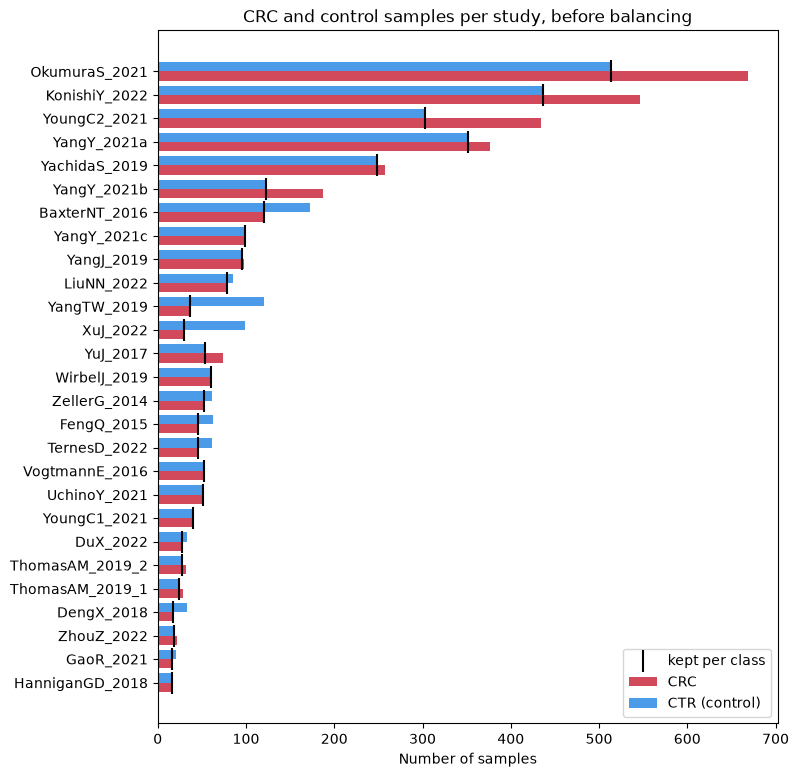

**Figure 1.** Before balancing there are 3,516 CRC and 3,263 control samples. The largest gap is in OkumuraS_2021 (669 CRC, 513 controls), and the most lopsided study is XuJ_2022, where only 23% of samples are CRC. Keeping the smaller class size in every study (black marks) leaves 5,966 samples, 2,983 per class, and drops 813 (12%).

In [3]:
order = before.sum(axis=1).sort_values().index
before_sorted = before.loc[order]
positions = np.arange(len(order))

fig, ax = plt.subplots(figsize=(8, 9))
ax.barh(positions - 0.2, before_sorted["CRC"], height=0.4, color="#D1495B", label="CRC")
ax.barh(positions + 0.2, before_sorted["CTR"], height=0.4, color="#4C9BE8", label="CTR (control)")
ax.scatter(kept.loc[order, "CRC"], positions, marker="|", s=250, color="black", zorder=3, label="kept per class")
ax.set_yticks(positions, order)
ax.set_xlabel("Number of samples")
ax.set_title("CRC and control samples per study, before balancing")
ax.legend(loc="lower right")

largest_gap = (before["CRC"] - before["CTR"]).abs().idxmax()
crc_share = before["CRC"] / before.sum(axis=1)
most_lopsided = (crc_share - 0.5).abs().idxmax()
dropped = len(crc_ctr) - len(flagged)
show_figure(
    fig,
    "balance_per_study",
    f"Before balancing there are {before['CRC'].sum():,} CRC and {before['CTR'].sum():,} control samples. "
    f"The largest gap is in {largest_gap} ({before.loc[largest_gap, 'CRC']} CRC, {before.loc[largest_gap, 'CTR']} controls), "
    f"and the most lopsided study is {most_lopsided}, where only {crc_share[most_lopsided]:.0%} of samples are CRC. "
    f"Keeping the smaller class size in every study (black marks) leaves {len(flagged):,} samples, "
    f"{len(flagged) // 2:,} per class, and drops {dropped:,} ({dropped / len(crc_ctr):.0%}).",
)

## 3. Save the balanced sample list

Notebook 03 builds the feature table from this list.

In [4]:
balanced_samples = flagged[["Cohort", "Assay", "Condition"]].reset_index()
balanced_samples.to_csv(PROCESSED / "balanced_samples.csv", index=False)
print(f"Saved {len(balanced_samples):,} rows to {PROCESSED.relative_to(PROJECT_ROOT).as_posix()}/balanced_samples.csv")

Saved 5,966 rows to data/processed/phase_1/02_balanced_subset/balanced_samples.csv


## 4. Checks

In [5]:
assert len(flagged) == 5966
assert (flagged["Condition"] == "CRC").sum() == 2983
assert flagged["Cohort"].nunique() == 27
assert len(pd.read_csv(PROCESSED / "balanced_samples.csv")) == 5966
print("All checks passed.")

All checks passed.
